In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix

C:\Users\Bruno\anaconda3\lib\site-packages\tensorflow\python\framework\dtypes.py:516: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
C:\Users\Bruno\anaconda3\lib\site-packages\tensorflow\python\framework\dtypes.py:517: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
C:\Users\Bruno\anaconda3\lib\site-packages\tensorflow\python\framework\dtypes.py:518: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
C:\Users\Bruno\anaconda3\lib\site-packages\tensorflow\python\framework\dtypes.py:519: FutureWarning: Passi

In [2]:
# Dataset directory
data_dir = "data"

# List only directories (ignore files like .txt)
classes = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
print("Classes found:", classes)

Classes found: ['Bacterialblight', 'Blast', 'Brownspot', 'Tungro']


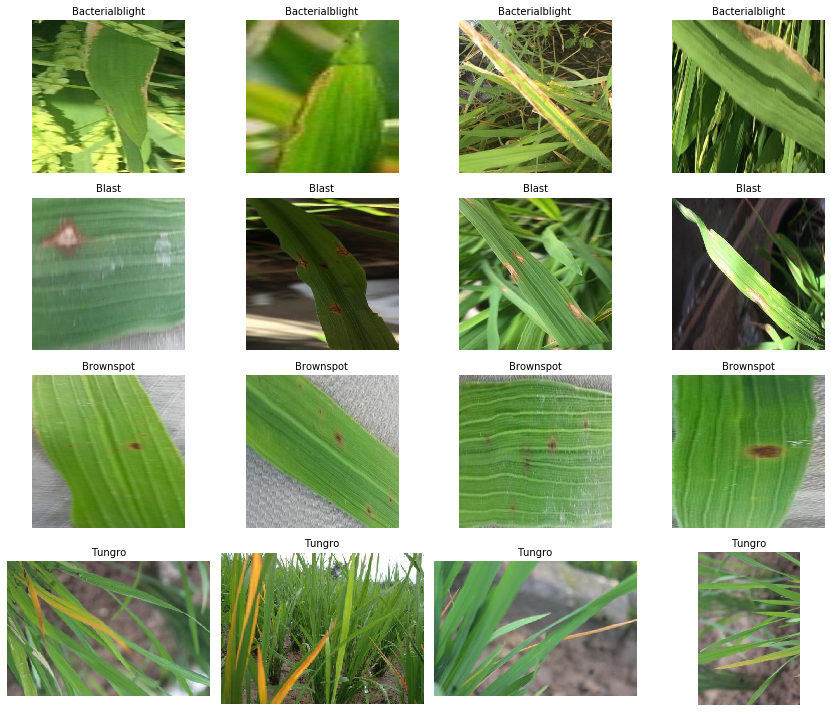

In [3]:
fig, axes = plt.subplots(len(classes), 4, figsize=(12, 10))
for i, cls in enumerate(classes):
    cls_path = os.path.join(data_dir, cls)
    sample_images = random.sample(os.listdir(cls_path), 4)
    for j, img_name in enumerate(sample_images):
        img_path = os.path.join(cls_path, img_name)
        img = plt.imread(img_path)
        axes[i, j].imshow(img)
        axes[i, j].axis("off")
        axes[i, j].set_title(cls, fontsize=10)
plt.tight_layout()
plt.show()

In [4]:
img_size = (128, 128)
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen = datagen.flow_from_directory(
    data_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
)

val_gen = datagen.flow_from_directory(
    data_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 4747 images belonging to 4 classes.
Found 1185 images belonging to 4 classes.


In [5]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(classes), activation='softmax')
])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Instructions for updating:
Call initializer instance with the dtype argument instead of passing it to the constructor
Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 126, 126, 32)      896       
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 63, 63, 32)        0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 61, 61, 64)        18496     
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 30, 30, 64)        0         
_________________________________________________________________
conv2d_2 (Conv2D)            (None, 28, 28, 128)       73856     
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 14, 14, 128)       0         
____

In [6]:
history = model.fit(
    train_gen,
    epochs=5,
    validation_data=val_gen
)

Epoch 1/5
149/149 [==============================] - 383s 3s/step - loss: 0.9299 - acc: 0.6130 - val_loss: 0.6433 - val_acc: 0.7840
Epoch 2/5
149/149 [==============================] - 100s 668ms/step - loss: 0.5400 - acc: 0.8045 - val_loss: 0.4672 - val_acc: 0.8118
Epoch 3/5
149/149 [==============================] - 64s 431ms/step - loss: 0.3263 - acc: 0.8780 - val_loss: 0.2131 - val_acc: 0.9257
Epoch 4/5
149/149 [==============================] - 126s 843ms/step - loss: 0.2218 - acc: 0.9149 - val_loss: 0.1701 - val_acc: 0.9333
Epoch 5/5
149/149 [==============================] - 145s 973ms/step - loss: 0.1401 - acc: 0.9499 - val_loss: 0.0702 - val_acc: 0.9747


In [9]:
history.history

{'loss': [0.93124478507951,
  0.540584811322785,
  0.3265187730532032,
  0.22098235866635227,
  0.14003519266875186],
 'acc': [0.61301875, 0.8045081, 0.8780282, 0.9148936, 0.9498631],
 'val_loss': [0.6433267883564296,
  0.467241632176171,
  0.2130863591538448,
  0.17014366483904028,
  0.07023063027545025],
 'val_acc': [0.78396624, 0.81181437, 0.9257384, 0.93333334, 0.9746835]}

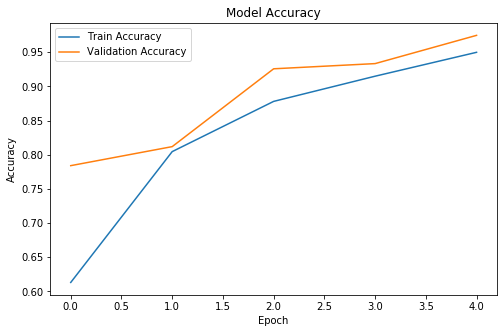

In [10]:
plt.figure(figsize=(8,5))
plt.plot(history.history['acc'], label='Train Accuracy')
plt.plot(history.history['val_acc'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [11]:
val_loss, val_acc = model.evaluate(val_gen)
print(f"Validation Accuracy: {val_acc*100:.2f}%")

38/38 [==============================] - 5s 124ms/step - loss: 0.0702 - acc: 0.9747
Validation Accuracy: 97.47%


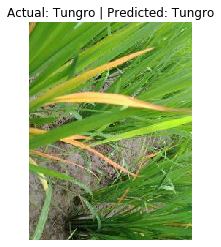

In [12]:
# Pick a random image from validation set
val_class = random.choice(classes)
val_class_path = os.path.join(data_dir, val_class)
random_image = random.choice(os.listdir(val_class_path))
img_path = os.path.join(val_class_path, random_image)

# Load image
from tensorflow.keras.preprocessing import image
img = image.load_img(img_path, target_size=img_size)
img_array = image.img_to_array(img)/255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)
predicted_class = classes[np.argmax(prediction)]

# Show result
plt.imshow(plt.imread(img_path))
plt.axis("off")
plt.title(f"Actual: {val_class} | Predicted: {predicted_class}")
plt.show()